# AI subscription payments and gross adds on card data (US, Omega 2022 panel)

Plan: `../plans/23rd_october_2026.txt`. Engine: `card_core_rules.py`. Cache: `../.cache/card_core/` (delete `raw.parquet` to re-pull; about 15 minutes on `ANALYST_XL`).

**Source.** `EARNEST.COMMON.TXNS_CORE_V`, `BRAND_ID IN (29847 ANTHROPIC, 27440 OPENAI, 32111 GOOGLE ONE, 29069 PERPLEXITY, 11021 FACEBOOK)`, 2022 consistent-shopper panel (`WEIGHT_AGG_CS2022 IS NOT NULL`), from 2023-01-01 (Google One from 2024-01-01 and above $3.50; Facebook from 2026-06-01).

**Brand gaps, patched by descriptor.** Several subscription merchants have no main brand in Omega's `MID_MATCH_V1_0`, so `TXNS_CORE` never picks them up. The notebook adds the panel's rows for these unbranded merchants from the Omega share, using `TXNS_CORE`'s row logic (same panel join, affected accounts excluded). Longer term, these merchants need mapping to the brands.
- **ChatGPT subscriptions are not under brand 27440.** Neither `OPENAI *CHATGPT SUBSCR ...` nor Play's `GOOGLE *CHATGPT` is branded, so they come from the patch: about 96% of ChatGPT rows. Brand 27440 itself holds `OPENAI OPENAI.COM`-style rows, mostly API credits.
- **Muse direct web (`METAPAY META.COM`) and Play (`GOOGLE MUSE FROM META`) are not under FACEBOOK.** Brand 11021 is mostly Facebook ad spend (`FACEBK *____`).
- **Older Claude web descriptors and Google Play:** `CLAUDEAI SUBSCRIPTION ...` (no dot; 2024 to early 2025, about 40% of Claude payments then) and `GOOGLE *CLAUDE BY ANTH...` are unbranded, as is most of Perplexity's Google Play (`GOOGLE *PERPLEXITY ...`).
- The patch takes every unbranded merchant matching `CHATGPT`, `OPENAI`, `CLAUDEAI` / `CLAUDE.AI` / `CLAUDE BY` / `ANTHROPIC`, `PERPLEX`, `METAPAY META.COM`, `MUSE FROM META` or Google One SKU codes. The classification rules then reject look-alikes and API rows, exactly as for branded rows.
- **Descriptor changes:** Perplexity's brandless Stripe descriptor (`PRO WWW.PERPLEX...`, 2026-06-08 to 10-04) and Google One's SKU-code descriptors (`GOOGLE G1SK003M`, `G1AI101M`, from 2026-09-15) are unbranded. Without them, Perplexity loses about 90% of its payments in Jun-Sep 2026, and Gemini about half from mid-September.

Grok and Cursor are not in the brand list and are out of scope.

In [1]:
import sys, warnings, pandas as pd, numpy as np, matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter, FuncFormatter
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message="This pattern is interpreted")
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 70); pd.set_option("display.max_rows", 200)
import card_core_rules as R

if not (R.CACHE / "raw.parquet").exists():
    R.pull()
raw = pd.read_parquet(R.CACHE / "raw.parquet")
panel = pd.read_parquet(R.CACHE / "panel.parquet").iloc[0]
N, W = panel.members, panel.weight_sum
END = raw.dt.max()
NAMES = {"chatgpt": "ChatGPT", "claude": "Claude", "gemini": "Gemini", "perplexity": "Perplexity", "muse": "Muse"}
COLORS = {"chatgpt": "#2a78d6", "claude": "#eb6834", "gemini": "#1baf7a", "perplexity": "#eda100", "muse": "#e87ba4"}
ORDER = list(NAMES)
PLANS = {"plus_M": "Plus", "go_M": "Go", "pro100_M": "Pro $100", "pro200_M": "Pro $200", "pro500_M": "Pro $500",
         "pro_M": "Pro (monthly)", "pro_A": "Pro (annual)", "max5_M": "Max 5x", "max20_M": "Max 20x",
         "ai_pro_M": "AI Pro (monthly)", "ai_pro_A": "AI Pro (annual)", "ai_plus_M": "AI Plus (monthly)",
         "ai_plus_A": "AI Plus (annual)", "ai_plus_2tb_M": "2TB incl. AI Plus (monthly)",
         "ai_plus_2tb_A": "2TB incl. AI Plus (annual)", "ultra_M": "Ultra", "ultra_5x_M": "Ultra 5x",
         "pro_disc_M": "Pro (discounted)", "max_M": "Max (monthly)", "max_A": "Max (annual)",
         "power_M": "Power"}
print(f"panel members {N:,.0f}, weight sum {W:,.0f}, data end {END.date()}")
(raw.assign(provider=raw.provider.map(NAMES))
    .groupby(["provider", "source"]).agg(rows=("transid", "size"), members=("memid", "nunique"),
                                         first=("dt", "min"), last=("dt", "max")))

panel members 3,605,781, weight sum 6,123,136, data end 2026-10-21


rows  members      first       last
provider   source                                                 
ChatGPT    omega_unbranded  2940625   345536 2023-01-01 2026-10-21
           txns_core         103428    28033 2023-01-01 2026-10-21
Claude     omega_unbranded    27287     6558 2023-01-04 2026-10-21
           txns_core         429944    66382 2023-09-07 2026-10-21
Gemini     omega_unbranded   305132   281584 2026-09-15 2026-10-21
           txns_core        1464750   281423 2024-01-01 2026-10-21
Muse       omega_unbranded      226      152 2026-06-09 2026-10-21
           txns_core         362368    78138 2026-06-01 2026-10-21
Perplexity omega_unbranded    10431     2987 2023-01-01 2026-10-21
           txns_core          26057     5293 2023-02-13 2026-10-21

## 1. Is the 2022 consistent-shopper panel fixed?

`CARDLINK_PANEL_V1_0` holds one row per member for `aggregate_consistent_shopper_2022_v2`. If every member has the same start date and one static weight, membership is fixed: nobody joins after the panel is drawn, so gross adds can be read as a share of a constant base.

In [2]:
import snowflake.connector as sc
cur = sc.connect(connection_name="default", warehouse="ANALYST_L").cursor()
cur.execute(f"""SELECT COUNT(*) AS rows_, COUNT(DISTINCT cardlinkid) AS members, COUNT(DISTINCT panel_start_date) AS start_dates,
        MIN(panel_start_date) AS first_start, MAX(panel_start_date) AS last_start,
        COUNT(*) - COUNT(DISTINCT cardlinkid, weight) AS members_with_2plus_weights,
        COUNT_IF(EXISTS (SELECT 1 FROM {R.OMEGA}_STATIC.AFFECTED_ACCOUNTS_092026 a WHERE a.cardlinkid = p.cardlinkid)) AS affected_excluded
    FROM {R.OMEGA}.CARDLINK_PANEL_V1_0 p WHERE panel = '{R.PANEL}'""")
pd.DataFrame(cur.fetchall(), columns=[d[0].lower() for d in cur.description]).T.rename(columns={0: "value"})

,value
rows_,3614559
members,3614559
start_dates,1
first_start,2022-01-01
last_start,2022-01-01
members_with_2plus_weights,0
affected_excluded,8778


A fixed list is not the same as a fixed **active** base: members can stop transacting. As a check, the chart below uses activity spells built earlier on the same panel (`../.cache/omega_spells.parquet`, a member is active while they have a transaction in the trailing 35 days).

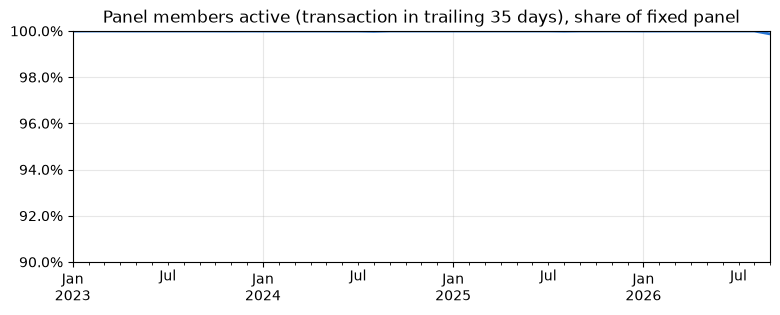

active at 2026-09-30: 3,609,959 of 3,614,668 (99.9%); lowest month-end since 2023: 99.9%


In [3]:
sp = pd.read_parquet(R.CACHE.parent / "omega_spells.parquet")
sp[["spell_start", "spell_end"]] = sp[["spell_start", "spell_end"]].apply(pd.to_datetime)
ids = pd.read_parquet(R.CACHE.parent / "omega_panel.parquet", columns=["cardlinkid"]).cardlinkid  # panel list as of 2026-10-19
sp = sp[sp.uid.isin(ids)]
NP = ids.nunique()
months = pd.date_range("2023-01-31", sp.spell_end.max(), freq="ME")
act = pd.Series([sp.uid[(sp.spell_start <= m) & (sp.spell_end + pd.Timedelta(days=35) >= m)].nunique() for m in months],
                index=months)
ax = (act / NP).plot(figsize=(9, 3), color="#2a78d6", lw=2, title="Panel members active (transaction in trailing 35 days), share of fixed panel")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1)); ax.set_ylim(0.9, 1.0); ax.grid(alpha=0.3); plt.show()
print(f"active at {months[-1].date()}: {act.iloc[-1]:,.0f} of {NP:,.0f} ({act.iloc[-1] / NP:.1%}); "
      f"lowest month-end since 2023: {(act / NP).min():.1%}")

**Finding: the panel is fixed.** All 3,614,559 members share one start date (2022-01-01) and one static weight. Nobody joins later. After `TXNS_CORE` drops 8,778 affected accounts, the denominator is **3,605,781** members (weighted: 6.12M).

The active base is also close to fixed: 99.9% of members had a transaction in the trailing 35 days at every month-end since 2023. That is survivor-like, as in the earlier card work. So "% of panel" here is effectively "% of active card users in the panel", which is directly comparable over time. It is not "% of the US population": the panel skews toward heavy card users, so treat it as a read-across.

## 2. Billing descriptions x pricing, by provider

For each provider, descriptors are grouped into families. For each family (debits only):
- **pct_on_price**: share of payments on a US consumer list price valid that day (from `../plans/{provider}_prices.csv`, list price to +12% sales tax).
- **pct_recurring**: share of payments where the same member pays again in the same family 26-35 days before or after (a monthly billing rhythm).
- **pct_both**: on price and recurring.

A subscription family should score high on both. A family that is off-price and on random dates (for example API credits or ad spend) is excluded, so it cannot create false gross adds.

In [4]:
RES = {}
def show(p):
    t, x = R.research(raw, p)
    RES[p] = x
    fmt = {c: "{:.0%}" for c in ["pct_on_price", "pct_recurring", "pct_both"]} | {"rows": "{:,}", "members": "{:,}", "median_amt": "${:,.2f}"}
    display(t.style.format(fmt))
    top = x.groupby("family").size().nlargest(4).index
    fig, axes = plt.subplots(1, len(top), figsize=(4 * len(top), 2.6), squeeze=False)
    for ax, f in zip(axes[0], top):
        a = x.loc[x.family == f, "amount"]
        ax.hist(a.clip(upper=a.quantile(0.99)), bins=60, color=COLORS[p])
        ax.set_title(f, fontsize=9); ax.tick_params(labelsize=8); ax.grid(alpha=0.3)
    fig.suptitle(f"{NAMES[p]}: amount distribution by descriptor family (clipped at p99)", fontsize=10); plt.tight_layout(); plt.show()

### Claude (brand 29847 ANTHROPIC)

,rows,members,first,last,median_amt,pct_on_price,pct_recurring,pct_both
family,,,,,,,,
CLAUDE.AI SUBSCRIPTION,"152,982","38,612",2023-09-07,2026-09-17,$21.20,96%,81%,78%
ANTHROPIC* CLAUDE SUB,"138,928","41,260",2024-09-06,2026-10-21,$21.20,96%,82%,80%
bare ANTHROPIC,"117,324","20,342",2023-01-04,2026-10-21,$12.59,39%,4%,2%
ANTHROPIC* CLAUDE,"26,143","7,997",2024-10-07,2026-10-20,$20.49,95%,85%,82%
Google Play,"10,379","2,847",2024-07-19,2026-10-21,$21.35,92%,83%,78%
ANTHROPIC* (other),"4,765","1,788",2026-05-30,2026-10-21,$21.45,95%,78%,75%
Team,"3,110",549,2024-07-13,2026-10-21,$133.25,6%,49%,2%
other,6,4,2026-03-30,2026-10-05,$20.00,100%,67%,67%


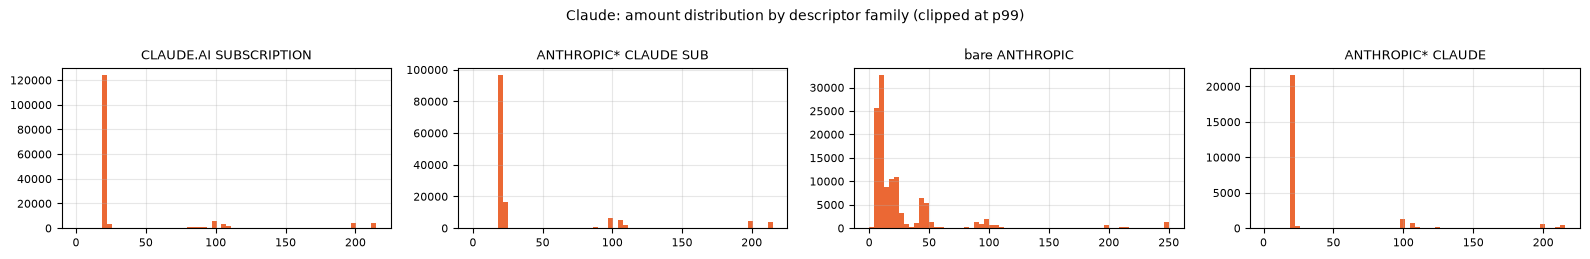

In [5]:
show("claude")

**Hypothesis: bare `ANTHROPIC` is not a plan.** Compare the day-of-month regularity and amounts of bare `ANTHROPIC` rows with the Claude subscription descriptors for the same members.

In [6]:
x = RES["claude"]
sub = x.family.isin(["CLAUDE.AI SUBSCRIPTION", "ANTHROPIC* CLAUDE SUB", "ANTHROPIC* CLAUDE"])
bare = x.family.eq("bare ANTHROPIC")
both_m = set(x.loc[sub, "memid"]) & set(x.loc[bare, "memid"])
def stats(m):
    g = x[m].sort_values(["memid", "dt"]).groupby("memid").dt.diff().dt.days
    return pd.Series({"rows": m.sum(), "members": x.loc[m, "memid"].nunique(),
                      "payments per member-month": x[m].groupby(["memid", x.dt.dt.to_period("M")]).size().mean(),
                      "median gap (days)": g.median(), "gap 26-35d": g.between(26, 35).mean(),
                      "amount on $20/$100/$200 (+tax)": x.loc[m, "on_price"].mean(),
                      "top amounts": ", ".join(f"${a:g}" for a in x.loc[m, "amount"].round(0).value_counts().head(6).index)})
pd.DataFrame({"subscription descriptors": stats(sub), "bare ANTHROPIC": stats(bare),
              "bare ANTHROPIC, members who also pay a sub": stats(bare & x.memid.isin(both_m))})

,subscription descriptors,bare ANTHROPIC,"bare ANTHROPIC, members who also pay a sub"
rows,318053,117324,93606
members,61328,20342,15126
payments per member-month,1.093375,3.003994,3.049353
median gap (days),30.0,1.0,1.0
gap 26-35d,0.664917,0.022979,0.023172
amount on $20/$100/$200 (+tax),0.957935,0.392324,0.390904
top amounts,"$20, $21, $22, $100, $200, $107","$5, $11, $10, $20, $45, $21","$5, $11, $10, $20, $45, $21"


**Finding: the hypothesis holds; bare `ANTHROPIC` is not a plan.**
- Bare `ANTHROPIC` rows come about 3 times per member-month, with a median gap of 1 day. Only 2% are 26-35 days apart, and the common amounts are $5 / $10 / $11 / $45: API credit top-ups and auto-reloads.
- The subscription descriptors (`CLAUDE.AI SUBSCRIPTION`, then `ANTHROPIC* CLAUDE SUB` / `ANTHROPIC* CLAUDE` from 2026-05-30) are about 96% on $20 / $100 / $200 plus tax, with a 30-day median gap.
- Most bare-`ANTHROPIC` payers (15.0k of 19.7k) also pay a subscription, so counting bare rows would double count members and create false adds. They are excluded, except about 1% that sit on an exact list price and repeat monthly.
- `Team` descriptors (median $133) are excluded.
- Google Play (`GOOGLE *CLAUDE BY ANTH…`, unbranded) behaves like a subscription and is kept.

### ChatGPT (brand 27440 OPENAI + unbranded CHATGPT)

,rows,members,first,last,median_amt,pct_on_price,pct_recurring,pct_both
family,,,,,,,,
CHATGPT SUBSCR,"2,536,479","290,094",2023-01-30,2026-10-21,$20.00,98%,90%,88%
Google Play,"260,094","43,246",2023-08-11,2026-10-21,$21.19,99%,89%,88%
bare OPENAI,"185,968","45,272",2023-01-01,2026-10-21,$20.00,67%,54%,51%
CHATGPT (other),"48,740","12,013",2023-01-14,2026-10-21,$20.00,84%,66%,62%


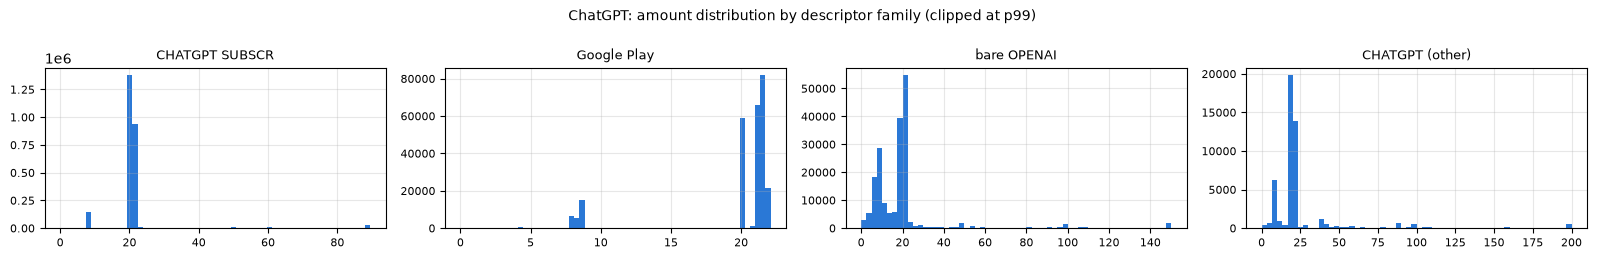

In [7]:
show("chatgpt")

**Finding.**
- `CHATGPT SUBSCR` and Google Play `GOOGLE *CHATGPT` are clean subscription families: 98-99% on price, about 90% recurring.
- Bare `OPENAI` is mixed. It is mostly API credits ($12 median, 30% recurring), but since late 2025 some ChatGPT subscriptions post under it. Those rows are kept only when the member repeats a plan price 25-35 days apart, which keeps 57% of the rows.
- `CHATGPT (other)` mixes credit packs, Business seats and Sora, and is filtered row by row.

### Gemini (brand 32111 GOOGLE ONE)

,rows,members,first,last,median_amt,pct_on_price,pct_recurring,pct_both
family,,,,,,,,
GOOGLE ONE,"1,315,141","272,334",2024-01-01,2026-10-21,$10.73,32%,67%,14%
Google One SKU code,"303,239","281,574",2026-09-15,2026-10-21,$2.13,8%,0%,0%
GOOGLE STORAGE,"116,677","57,957",2024-01-01,2026-10-17,$10.71,23%,55%,0%
GOOGLE ONE AI PREMIUM,"15,145","4,593",2024-04-23,2025-03-08,$20.93,100%,87%,87%
other,"2,714","1,025",2024-01-04,2026-10-19,$19.99,89%,74%,71%


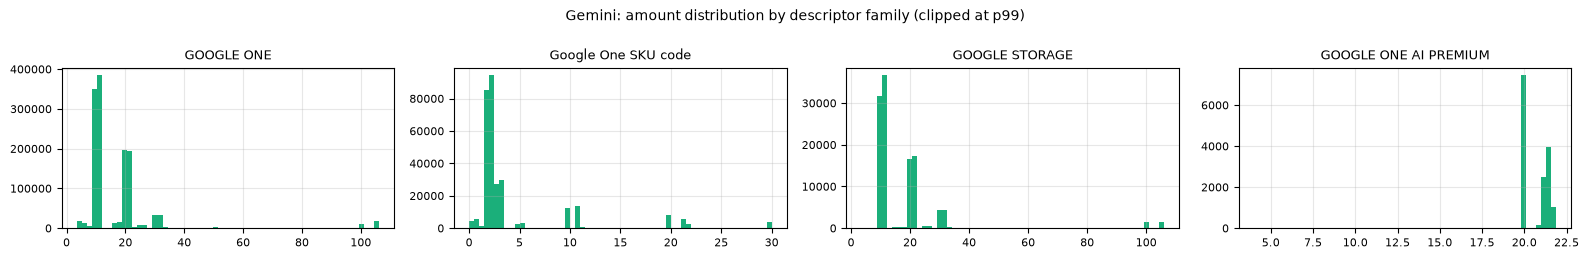

In [8]:
show("gemini")

**Finding.**
- There is no Gemini-specific descriptor. AI plans and storage both bill as `GOOGLE ONE`, so the plan is read from the amount, and price collisions are resolved by each member's payment rhythm. Only 32% of `GOOGLE ONE` rows are AI-tier payments; the rest are storage.
- The 2024-25 `GOOGLE ONE AI PREMIUM` descriptor is AI-only (100% kept).
- From 2026-09-15 Google bills with SKU codes (`G1AI101M` / `G1SK003M`, unbranded). Most of those rows are $1.99-2.99 storage.
- The Aug-Sep 2026 dip in Gemini subscribers coincides with that descriptor transition and also shows in the earlier keyword extract. It is likely a billing or descriptor artefact, not real churn.

### Perplexity (brand 29069)

,rows,members,first,last,median_amt,pct_on_price,pct_recurring,pct_both
family,,,,,,,,
WWW.PERPLEXITY.AI,"24,083","5,111",2023-01-01,2026-10-21,$20.00,79%,75%,65%
PERPLEXITY PRO,"5,039","1,817",2024-12-03,2026-10-21,$20.00,92%,82%,76%
credits / API,"3,618",881,2026-06-02,2026-10-21,$17.25,22%,8%,3%
Google Play,"2,920",593,2023-11-04,2026-10-21,$21.24,90%,74%,73%
Enterprise,490,162,2026-06-11,2026-10-21,$42.40,2%,80%,2%


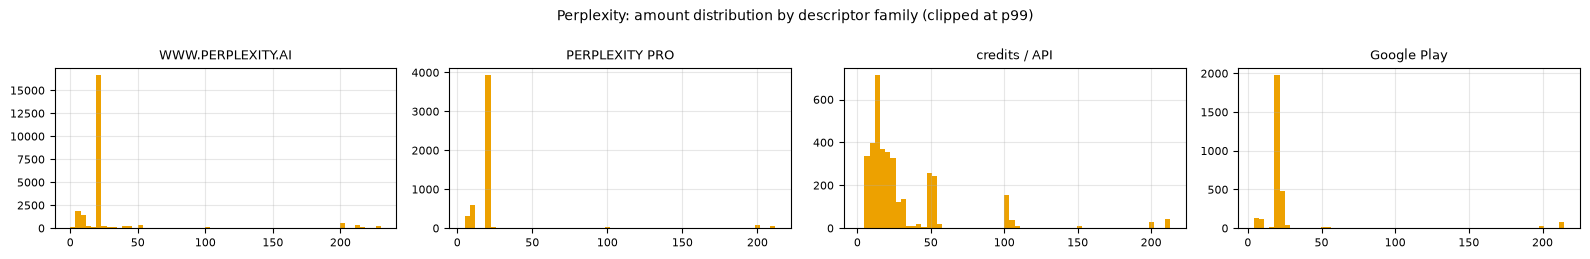

In [9]:
show("perplexity")

**Finding.**
- Web (`WWW.PERPLEXITY.AI`) and Google Play are subscription families: about 80-90% on price, about 75% recurring.
- From 2026-06-08 to 10-04 the Stripe descriptor dropped the brand (`PRO WWW.PERPLEX…`, unbranded). The patch recovers most of it, but the generic forms (`PRO, SAN FRANCISCO, CA`, bare `PRO`) can't be matched safely. This leaves a ~20% dip over that window.
- Credits / API and Enterprise rows are excluded.

### Muse (brand 11021 FACEBOOK + unbranded METAPAY)

,rows,members,first,last,median_amt,pct_on_price,pct_recurring,pct_both
family,,,,,,,,
FACEBK (ads),"200,029","20,327",2026-06-01,2026-10-21,$18.00,8%,5%,0%
other,"59,898","23,186",2026-06-01,2026-10-21,$52.35,8%,18%,1%
GOOGLE *FACEBOOK (Play),"30,186","8,483",2026-06-01,2026-10-21,$2.66,3%,59%,1%
PayPal / Meta Platforms,"29,892","6,187",2026-06-01,2026-10-21,$8.72,22%,22%,12%
METAPAY META.COM (web),195,123,2026-06-09,2026-10-21,$16.00,51%,51%,18%
GOOGLE *MUSE FROM META,31,29,2026-10-07,2026-10-20,$21.40,87%,0%,0%


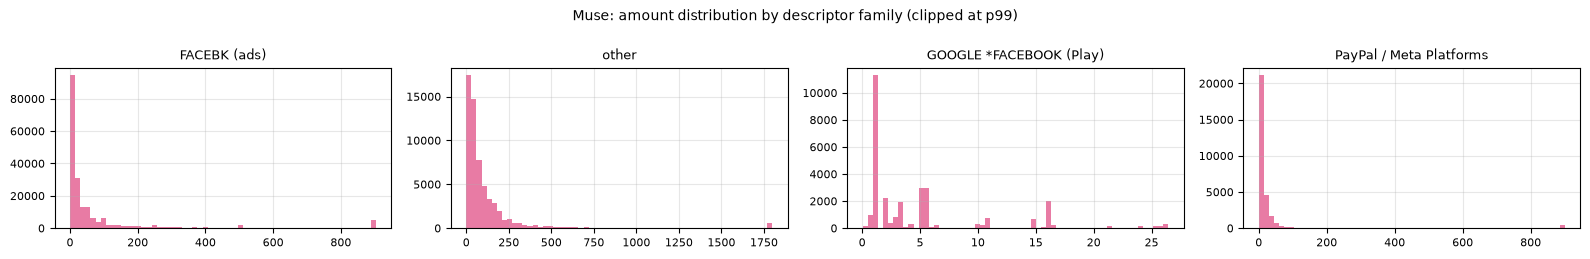

In [10]:
show("muse")

**Finding: Muse is barely visible on cards.**
- Brand 11021 is Facebook ad spend and in-app purchases. Its `GOOGLE *FACEBOOK` Play rows are mostly under $3 and can't be told apart from other Facebook purchases.
- Muse's own descriptors are tiny in this panel: `METAPAY META.COM` has 195 rows (about a third are pre-Muse Meta One look-alikes), and `GOOGLE *MUSE FROM META` has 31 rows from 2026-10-07.
- About 90 TR30 subscribers is too few to read. Most Muse billing is likely Apple, or not yet in the panel. The e-receipt data is the better source for Muse.

## 3. Classification rules

The families above line up with the descriptor rules researched on the same panel on 2026-10-19 (`../filters/{provider}.py`, reports in `../filters/*_report.md`). The rows here have the same descriptors (Omega `MERCHDESC` = `BILLING_DESCRIPTION`), so those rules are applied unchanged:

| Provider | Kept as a plan payment | Excluded |
|---|---|---|
| Claude | `CLAUDE.AI SUBSCRIPTION`, `ANTHROPIC* CLAUDE (SUB)`, Google Play `GOOGLE *CLAUDE`, on Pro $20 / Max $100 / $200 bands (+tax; $200 = Max 20x if repeated 25-40 days apart, else Pro annual) | bare `ANTHROPIC` (API credits) unless on a list price and repeated 26-35 days apart; Team; refunds; duplicates |
| ChatGPT | `CHATGPT SUBSCR`, Google Play `GOOGLE *CHATGPT`, on Go $8 / Plus $20 / Pro $100 / $200 / $500 bands | bare `OPENAI` (API) unless on a plan price and repeated 25-35 days apart; Team/Business seat multiples; credit packs |
| Gemini | Google One at AI-tier prices: AI Pro $19.99, AI Plus, Ultra; 2TB from 2026-01-27 (`ai_plus_2tb`, now includes AI Plus) | storage-only prices; $19.99 / $99.99 / $199.99 one-offs read as annual storage where the collision applies |
| Perplexity | `WWW.PERPLEXITY.AI`, `PERPLEXITY PRO`, Google Play, on Pro $20 / $200 annual, Max $200 / $2,000 | Enterprise seats, API / Computer credits, merch |
| Muse | `METAPAY META.COM` at Power $16 / Max $80 (+tax), Google Play `GOOGLE *MUSE FROM META` at $20 / $100, from 2026-09-07 | pre-Muse Meta One look-alikes on `METAPAY`; Facebook ads; `GOOGLE *FACEBOOK` (in-app purchases, not identifiable as Muse) |

In [11]:
cls = R.classify(raw)
cls["provider_name"] = cls.provider.map(NAMES)
print("kept vs excluded rows by provider and reason")
cls.pivot_table(index="reason", columns="provider_name", values="dt", aggfunc="size", fill_value=0).sort_values("Claude", ascending=False)

kept vs excluded rows by provider and reason


provider_name,ChatGPT,Claude,Gemini,Muse,Perplexity
reason,,,,,
ok,2801548,320486,483583,92,27119
api_usage,0,115176,0,0,0
duplicate,58783,12268,5043,0,889
refund,11285,3640,0,0,0
team,0,3162,0,0,0
out_of_band,12214,1175,0,28,0
auth,0,186,0,0,0
bank_fee,0,71,0,0,0
other_product,0,67,0,0,0


In [12]:
# how each research family was treated: share of rows kept
fam = pd.concat([RES[p][["transid", "family"]].assign(provider=p) for p in ORDER])
k = raw[["transid", "memid", "dt", "amount"]].merge(fam, on="transid").assign(amount=lambda d: d.amount.round(2))
kept = cls.loc[cls.keep, ["memid", "dt", "amount", "provider", "keep"]].assign(amount=lambda d: d.amount.round(2))
k = k.merge(kept.drop_duplicates(["memid", "dt", "amount", "provider"]), on=["memid", "dt", "amount", "provider"],
            how="left").fillna({"keep": False})
(k.groupby(["provider", "family"]).agg(rows=("transid", "size"), pct_kept=("keep", "mean"))
   .sort_values(["provider", "rows"], ascending=[True, False]).style.format({"rows": "{:,}", "pct_kept": "{:.0%}"}))

In [13]:
pay = cls[cls.keep].copy()
pay = pay.merge(raw.drop_duplicates("memid")[["memid", "weight"]], on="memid", how="left")
pay["plan_name"] = pay.provider.map(NAMES) + " " + pay.plan.astype(str).map(lambda c: PLANS.get(c, c))
print(f"{len(pay):,} plan payments, {pay.memid.nunique():,} members")
pay.pivot_table(index="plan_name", columns="channel", values="dt", aggfunc="size", fill_value=0)

3,633,547 plan payments, 434,391 members


channel,google_play,web
plan_name,,
ChatGPT Go,26186,165059
ChatGPT Plus,217954,2374238
ChatGPT Pro $100,437,6814
ChatGPT Pro $200,517,10339
ChatGPT Pro $500,1,3
Claude Max 20x,115,10210
Claude Max 5x,509,30397
Claude Pro (annual),104,9997
Claude Pro (monthly),9370,259784


**Cross-check against the earlier keyword extract.** The Oct-19 card tracker found candidates by keyword across all Omega merchants (`../.cache/metrics_omega/payments.parquet`, data to 2026-10-17). Comparing monthly kept payments shows whether the brand filter misses merchants.

In [14]:
old = pd.read_parquet(R.CACHE.parent / "metrics_omega" / "payments.parquet")
old = old[old.keep & old.provider.isin(ORDER) & (old.dt < "2026-10-01")]
new = pay[pay.dt < "2026-10-01"]
cmp = pd.concat({"keyword extract (Oct-19)": old.groupby(["provider", pd.to_datetime(old.dt).dt.to_period("M")]).size(),
                 "TXNS_CORE + patch": new.groupby(["provider", new.dt.dt.to_period("M")]).size()}, axis=1).fillna(0)
cmp["ratio"] = cmp.iloc[:, 1] / cmp.iloc[:, 0]
r = cmp.reset_index().pivot(index="dt", columns="provider", values="ratio").loc["2024-01":]
r.columns = [NAMES[c] for c in r.columns]
r.iloc[::3].style.format("{:.2f}")

,ChatGPT,Claude,Gemini,Muse,Perplexity
dt,,,,,
2024-01,1.00,1.00,nan,nan,1.00
2024-04,1.00,1.00,1.67,nan,1.00
2024-07,1.00,1.00,2.04,nan,1.00
2024-10,1.00,1.00,1.96,nan,1.00
2025-01,1.00,1.00,2.07,nan,1.00
2025-04,1.00,1.00,0.96,nan,1.00
2025-07,1.00,1.00,0.96,nan,1.00
2025-10,1.00,1.00,0.96,nan,1.00
2026-01,1.00,1.00,0.97,nan,1.00


**Finding: with the patch, the brand pull matches the earlier keyword extract.**
- ChatGPT, Claude and Perplexity agree at a ratio of 1.00 (Perplexity is 0.93 in Jul-Sep 2026, the brandless-descriptor window).
- Gemini shows about 2x more AI Pro payments in 2024. The brand pull catches `GOOGLE *ONE AI PREMIUM…` descriptors that the old keyword prefilter missed, so the new series is the better one.
- Without the patch, ChatGPT would be about 3% of its true level, Claude about 57% before 2025, Perplexity about 10% in Jun-Sep 2026, and Gemini about half from mid-September 2026. The brands need these merchants mapped before `TXNS_CORE` can be used on its own.

## 4. Daily and TR30 subscriber payments and gross adds

- **Subscriber payments (daily):** distinct members with a plan payment that day.
- **TR30 subscribers:** distinct members with a plan payment in the trailing 30 days (day d-29 to d).
- **Gross add:** a member's plan payment with no payment for the same provider (or plan) in the previous 75 days (400 days after an annual payment). Reactivations count. Reported from 2024-01-01, so every add has at least a year of lookback. At plan level, a plan switch is an add for the new plan.
- **% of panel:** count / fixed panel members (unweighted), and weighted count / sum of panel weights.

Caveats:
- TR30 counts payers, so annual-plan subscribers only appear in the month they pay. Annual plans are a small share (see the plan table at the end).
- The last ~10 days are still filling (late-posting transactions); they are shaded grey.
- Cards only see web and Google Play billing. Apple App Store subscriptions are invisible.

In [15]:
P = R.daily(pay, "provider")
PW = R.daily(pay, "provider", weight="weight")
L = R.daily(pay, "plan_name")
tr = P["tr30_subs"][ORDER]
last = tr.index[-1]
summary = pd.DataFrame({
    "TR30 subscribers": tr.iloc[-1], "% of panel": tr.iloc[-1] / N, "% of panel (weighted)": PW["tr30_subs"][ORDER].iloc[-1] / W,
    "TR30 gross adds": P["tr30_adds"][ORDER].iloc[-1], "gross adds % of panel": P["tr30_adds"][ORDER].iloc[-1] / N,
    "share of TR30 subs": tr.iloc[-1] / tr.iloc[-1].sum(),
    "TR30 subs 1y ago": tr.loc[last - pd.Timedelta(days=364)]}).rename(index=NAMES)
print(f"as of {last.date()} (latest days still filling; see charts)")
summary.style.format({"TR30 subscribers": "{:,.0f}", "TR30 gross adds": "{:,.0f}", "TR30 subs 1y ago": "{:,.0f}",
                      "% of panel": "{:.2%}", "% of panel (weighted)": "{:.2%}", "gross adds % of panel": "{:.3%}", "share of TR30 subs": "{:.1%}"})

as of 2026-10-21 (latest days still filling; see charts)


,TR30 subscribers,% of panel,% of panel (weighted),TR30 gross adds,gross adds % of panel,share of TR30 subs,TR30 subs 1y ago
provider,,,,,,,
ChatGPT,"200,044",5.55%,5.38%,"28,917",0.802%,67.6%,"95,158"
Claude,"36,638",1.02%,1.10%,"5,850",0.162%,12.4%,"4,603"
Gemini,"57,459",1.59%,1.52%,"13,835",0.384%,19.4%,"6,954"
Perplexity,"1,780",0.05%,0.05%,499,0.014%,0.6%,"1,016"
Muse,87,0.00%,0.00%,85,0.002%,0.0%,0


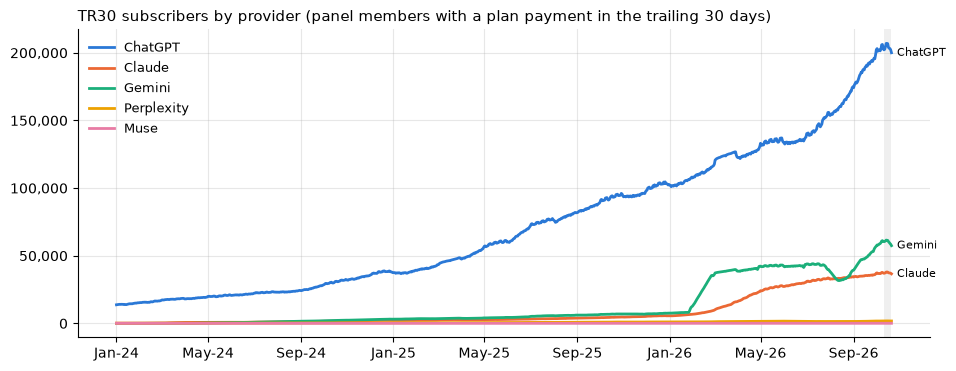

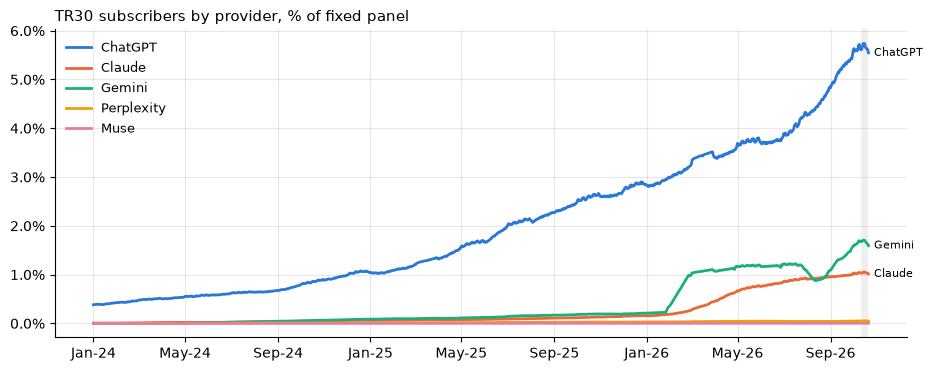

In [16]:
def style(ax, title, pct=False, dec=1):
    ax.set_title(title, fontsize=11, loc="left")
    ax.axvspan(END - pd.Timedelta(days=10), END, color="#999", alpha=0.15, lw=0)
    ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=dec) if pct else FuncFormatter(lambda v, _: f"{v:,.0f}"))

def lines(df, title, pct=False, dec=1, ax=None):
    ax = ax or plt.subplots(figsize=(11, 4))[1]
    top = df.iloc[-1].max()
    for p in [c for c in ORDER if c in df]:
        ax.plot(df.index, df[p], color=COLORS[p], lw=2, label=NAMES[p])
        if df[p].iloc[-1] > 0.05 * top:  # direct-label the visible lines; the legend covers the rest
            ax.annotate(NAMES[p], (df.index[-1], df[p].iloc[-1]), xytext=(4, 0), textcoords="offset points", fontsize=8, va="center")
    style(ax, title, pct, dec); ax.legend(loc="upper left", frameon=False, fontsize=9)
    return ax

lines(tr, "TR30 subscribers by provider (panel members with a plan payment in the trailing 30 days)"); plt.show()
lines(tr / N, "TR30 subscribers by provider, % of fixed panel", pct=True, dec=1); plt.show()

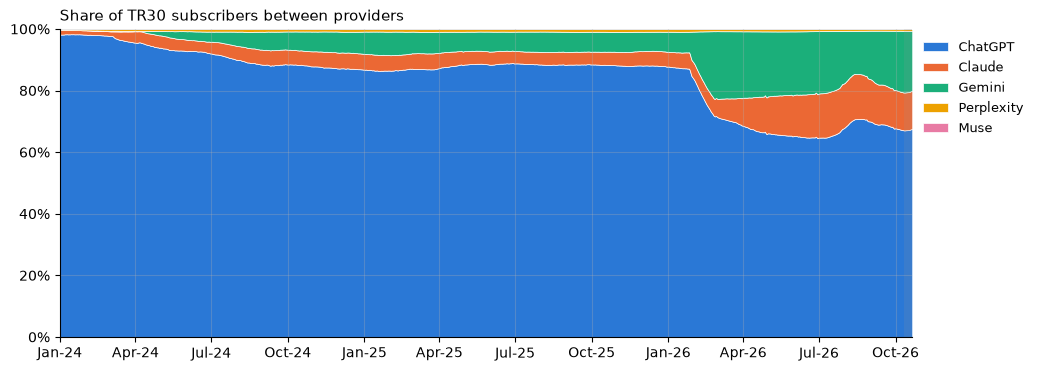

provider,ChatGPT,Claude,Gemini,Perplexity,Muse
2024-03-31,95.6%,3.7%,0.2%,0.6%,0.0%
2024-06-30,92.0%,3.8%,3.3%,0.9%,0.0%
2024-09-30,88.5%,4.8%,5.9%,0.8%,0.0%
2024-12-31,86.8%,5.1%,7.2%,0.9%,0.0%
2025-03-31,87.2%,4.9%,6.9%,0.9%,0.0%
2025-06-30,88.8%,4.0%,6.3%,0.9%,0.0%
2025-09-30,88.5%,4.1%,6.5%,0.9%,0.0%
2025-12-31,87.8%,4.8%,6.5%,0.9%,0.0%
2026-03-31,68.6%,9.0%,21.6%,0.8%,0.0%
2026-06-30,64.6%,14.3%,20.5%,0.7%,0.0%


In [17]:
share = tr.div(tr.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(11, 4))
ax.stackplot(share.index, *[share[p] for p in ORDER], colors=[COLORS[p] for p in ORDER], labels=[NAMES[p] for p in ORDER],
             edgecolor="white", linewidth=0.5)
style(ax, "Share of TR30 subscribers between providers", pct=True, dec=0); ax.set_ylim(0, 1); ax.margins(x=0)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False, fontsize=9); plt.show()
share.resample("QE").last().rename(columns=NAMES, index=lambda d: d.date()).style.format("{:.1%}")

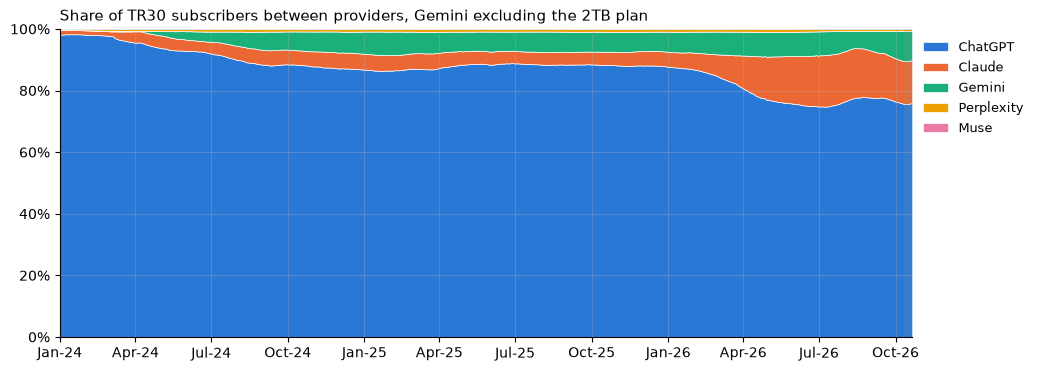

In [18]:
# the 2TB plan counts as Gemini AI Plus from 2026-01-27 (earlier decision); without it Gemini's share is much smaller
g2 = R.tr_distinct(pay[pay.provider.ne("gemini") | ~pay.plan.astype(str).str.startswith("ai_plus_2tb")], "provider", tr.index)[ORDER]
sh2 = g2.div(g2.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(11, 4))
ax.stackplot(sh2.index, *[sh2[p] for p in ORDER], colors=[COLORS[p] for p in ORDER], labels=[NAMES[p] for p in ORDER],
             edgecolor="white", linewidth=0.5)
style(ax, "Share of TR30 subscribers between providers, Gemini excluding the 2TB plan", pct=True, dec=0); ax.set_ylim(0, 1); ax.margins(x=0)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False, fontsize=9); plt.show()

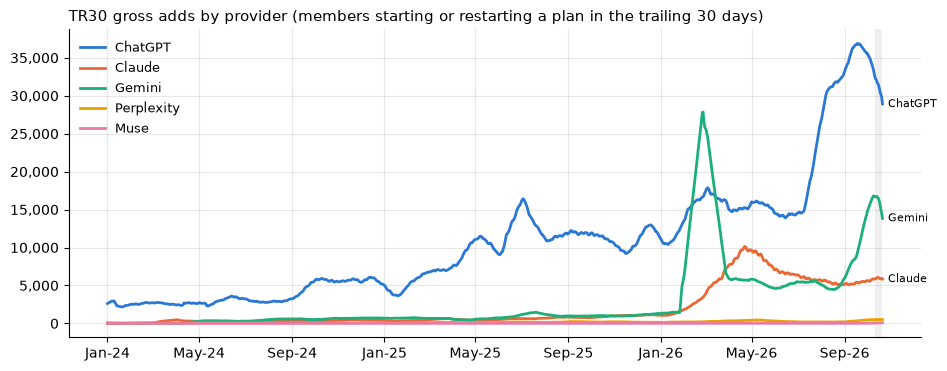

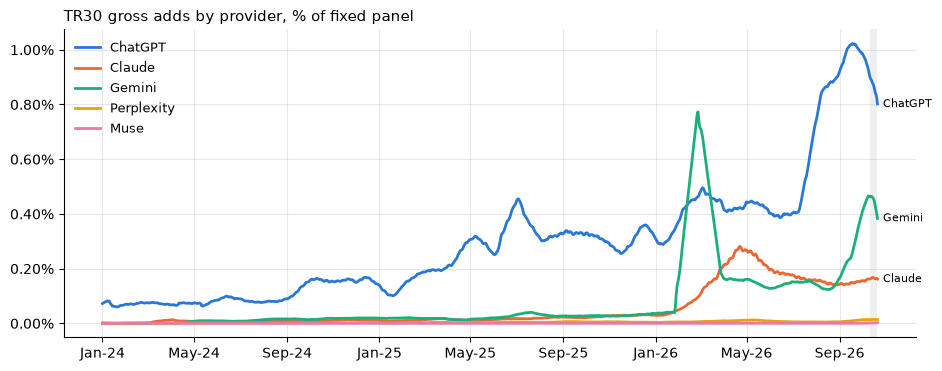

In [19]:
lines(P["tr30_adds"][ORDER], "TR30 gross adds by provider (members starting or restarting a plan in the trailing 30 days)"); plt.show()
lines(P["tr30_adds"][ORDER] / N, "TR30 gross adds by provider, % of fixed panel", pct=True, dec=2); plt.show()

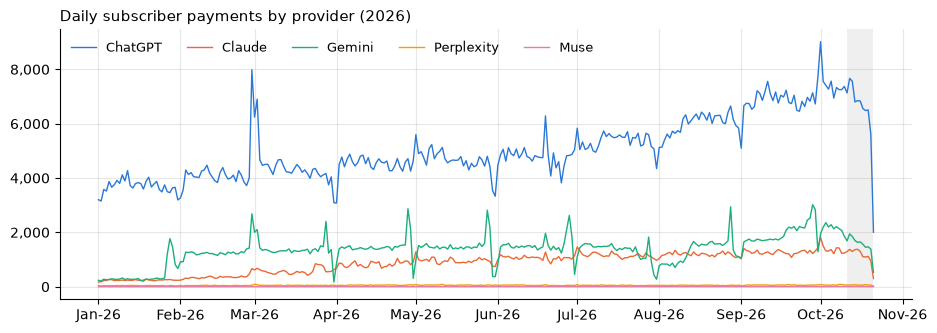

In [20]:
fig, ax = plt.subplots(figsize=(11, 3.5))
d = P["payments"][ORDER].loc["2026-01-01":]
for p in ORDER:
    ax.plot(d.index, d[p], color=COLORS[p], lw=1, label=NAMES[p])
style(ax, "Daily subscriber payments by provider (2026)"); ax.legend(loc="upper left", frameon=False, fontsize=9, ncol=5); plt.show()

**Findings (TR30, data to 2026-10-21; the last ~10 days are still filling).**
- **ChatGPT:** about 200k members, 5.5% of the panel, up from 95k a year ago. Gross adds stepped up sharply in Aug-Sep 2026 (TR30 adds peaked at about 37k).
- **Claude:** 36.6k, 1.0% of the panel, up about 8x on the year. Most of the growth came in Feb-May 2026, when TR30 adds peaked at about 10k.
- **Gemini:** 57k, 1.6% of the panel. **Most of that comes from the 2TB plan, counted as AI Plus from 2026-01-27** (an earlier decision). That rule also creates a one-off spike of about 28k "gross adds" in Feb 2026, when existing 2TB subscribers were reclassified rather than signing up. Excluding 2TB, Gemini is about 24k (0.7%).
- **Perplexity:** about 1.8k (0.05%). **Muse:** too small to read on cards.
- **Share of TR30 subscribers:** ChatGPT about 68%, Gemini 19%, Claude 12%. Excluding Gemini's 2TB plan: ChatGPT about 76%, Claude about 14%, Gemini about 9%.
- Weighted and unweighted panel shares are within about 0.2pp of each other.

## 5. TR30 subscribers by plan

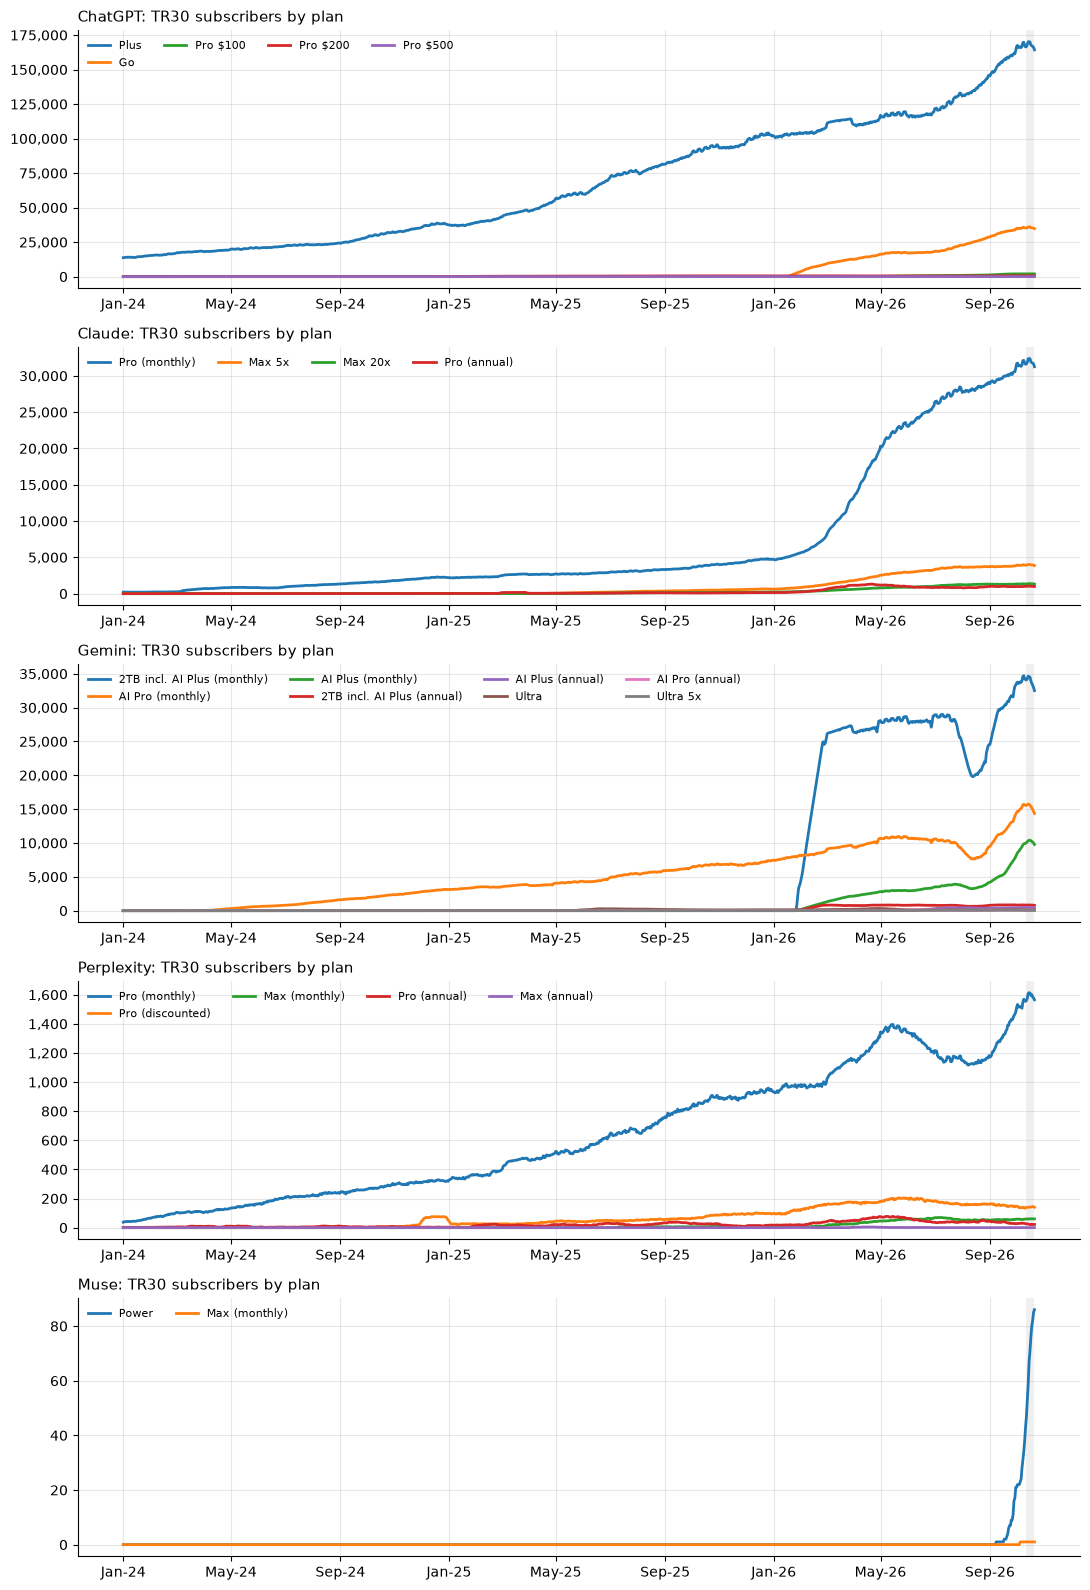

In [21]:
fig, axes = plt.subplots(len(ORDER), 1, figsize=(11, 3.2 * len(ORDER)))
for ax, p in zip(axes, ORDER):
    cols = [c for c in L["tr30_subs"].columns if c.startswith(NAMES[p] + " ")]
    d = L["tr30_subs"][cols]
    d = d[d.iloc[-1].sort_values(ascending=False).index]
    for i, c in enumerate(d.columns):
        ax.plot(d.index, d[c], lw=2, color=plt.cm.tab10(i), label=c.split(" ", 1)[1])
    style(ax, f"{NAMES[p]}: TR30 subscribers by plan"); ax.legend(loc="upper left", frameon=False, fontsize=8, ncol=4)
plt.tight_layout(); plt.show()

In [22]:
pl = pd.DataFrame({"TR30 subscribers": L["tr30_subs"].iloc[-1], "% of panel": L["tr30_subs"].iloc[-1] / N,
                   "TR30 gross adds": L["tr30_adds"].iloc[-1], "gross adds % of panel": L["tr30_adds"].iloc[-1] / N})
pl = pl[pl["TR30 subscribers"] > 0].sort_values("TR30 subscribers", ascending=False)
pl.style.format({"TR30 subscribers": "{:,.0f}", "TR30 gross adds": "{:,.0f}", "% of panel": "{:.3%}", "gross adds % of panel": "{:.3%}"})

,TR30 subscribers,% of panel,TR30 gross adds,gross adds % of panel
plan_name,,,,
ChatGPT Plus,"164,330",4.557%,"23,654",0.656%
ChatGPT Go,"34,826",0.966%,"6,322",0.175%
Gemini 2TB incl. AI Plus (monthly),"32,512",0.902%,"4,765",0.132%
Claude Pro (monthly),"31,258",0.867%,"5,271",0.146%
Gemini AI Pro (monthly),"14,371",0.399%,"3,634",0.101%
Gemini AI Plus (monthly),"9,776",0.271%,"5,727",0.159%
Claude Max 5x,"3,875",0.107%,845,0.023%
ChatGPT Pro $100,"2,013",0.056%,407,0.011%
Perplexity Pro (monthly),"1,565",0.043%,464,0.013%


**Findings by plan.**
- **ChatGPT Plus:** about 164k members, 4.4% of the panel.
- **ChatGPT Go:** about 35k, 0.9% of the panel. It launched 2026-01-16, so roughly 1 in 6 paying ChatGPT members on cards is on Go.
- **Claude Pro (monthly):** 31k, 0.87%. Max 5x is 3.9k and Max 20x is 1.3k.
- **Gemini:** AI Pro (monthly) is 14k and AI Plus (monthly) is 10k.
- **Annual plans:** each is under 1k TR30 payers, because annual subscribers only appear in the month they pay. A subscriber count for annual plans would need a 365-day window.

In [23]:
# export for later comparison with the e-receipt panel
out = {f"{k}_{lvl}": v for lvl, D in [("provider", P), ("plan", L)] for k, v in D.items()}
pd.concat(out, axis=1).to_parquet(R.CACHE / "daily_metrics.parquet")
print("saved", R.CACHE / "daily_metrics.parquet")

saved C:\Users\fintan.creedon\code\exploration\ai\.cache\card_core\daily_metrics.parquet
